In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import glob

from itertools import combinations
import sys
from statsmodels.stats.multitest import multipletests
from scipy.stats import norm
import os
import pickle

In [2]:
import helper_functions as hf

In [3]:
plt.rcParams.update({'font.size': 14})

## Figure 1 (kinetic model)

In [4]:
!mkdir figures

### A (kinetic model)

Rendered in latex

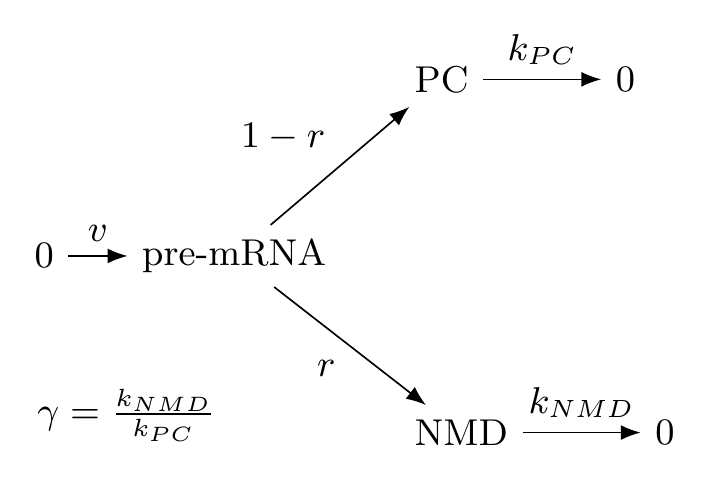

In [5]:
import subprocess
from pathlib import Path
from IPython.display import display, IFrame

tex_source = r"""
\documentclass[tikz,border=5pt]{standalone}
\usepackage{amsmath}
\usepackage{tikz}
\usetikzlibrary{positioning,arrows.meta,calc}

\begin{document}

\begin{tikzpicture}[
    node distance=1cm and 0.5cm,
    every node/.style={font=\small},
    >=Latex
]

\node (A) at (0,0) {0};
\node[right=of A] (B) {pre-mRNA};
\node[above right=of B] (C) {PC};
\node[below right=of B] (D) {NMD};
\node[right = 1cm of C] (E) {0};
\node[right = 1cm of D] (F) {0};



%\node (G) [below = of A] at ($(A) + (0.5, 0.5)$) {$\gamma = \frac{k_{NMD}}{k_{PC}}$};

\node (G) [below = of A] at ($(A) + (0.7, 0)$) {$\gamma = \frac{k_{NMD}}{k_{PC}}$};

\draw[->] (A) -- node[above] {$v$} (B);
\draw[->] (B) -- node[above left] {$1-r$} (C);
\draw[->] (B) -- node[below left] {$r$} (D);
\draw[->] (C) -- node[above] {$k_{PC}$} (E);
\draw[->] (D) -- node[above] {$k_{NMD}$} (F);


\end{tikzpicture}

\end{document}
"""

tex_path = Path('./figures/scheme.tex')

tex_path.write_text(tex_source, encoding="utf-8")

result = subprocess.run(
    [
        "pdflatex",
        "-interaction=nonstopmode",
        "-halt-on-error",
        tex_path.name
    ],
    cwd=tex_path.parent,
    capture_output=True,
    text=True
)

if result.returncode==0:

    from pdf2image import convert_from_path
    from IPython.display import display
    
    pages = convert_from_path("./figures/scheme.pdf", dpi=300)
    
    display(pages[0])
else:
    print(result.stderr)

### B (theoretical r = f(psi,gamma))

(-0.05, 1.05, -0.05, 1.05)

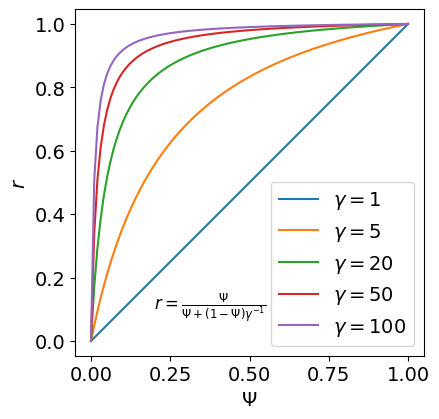

In [6]:
f,ax = plt.subplots(figsize=(4.5,4.5))
psi = np.linspace(0,1,100)
for gamma in [1,5,20,50,100]:
    r = hf.psi2r(psi,gamma)
    ax.plot(psi,r,label=f'$\gamma={gamma}$')
ax.legend()
ax.set_xlabel('$\Psi$')
ax.set_ylabel('$r$')
ax.text(0.2,0.1,r'$r = \frac{\Psi}{\Psi + (1-\Psi)\gamma^{-1}}$',fontsize=12)
ax.axis('equal')

In [7]:
f.savefig('./figures/r_from_psi_theory.pdf',bbox_inches='tight')

In [8]:
from pypdf import PdfReader, PdfWriter, PageObject

def merge_pdfs(pdf1, pdf2, out_pdf="merged.pdf"):
    reader1 = PdfReader(pdf1)
    reader2 = PdfReader(pdf2)

    # Берем первые страницы обоих документов
    page1 = reader1.pages[0]
    page2 = reader2.pages[0]

    # 1. Находим целевую (максимальную) высоту
    h1 = float(page1.mediabox.height)
    h2 = float(page2.mediabox.height)
    target_height = max(h1, h2)

    # 2. Масштабируем страницы по высоте с сохранением пропорций
    scale1 = target_height / h1
    page1.scale_by(scale1)
    
    scale2 = target_height / h2
    page2.scale_by(scale2)

    # 3. Получаем новую ширину страниц после масштабирования
    w1_new = float(page1.mediabox.width)
    w2_new = float(page2.mediabox.width)

    # Вычисляем итоговые размеры общего листа
    total_width = w1_new + w2_new

    # 4. Создаем пустой холст нужного размера
    combined_page = PageObject.create_blank_page(width=total_width, height=target_height)

    # 5. Размещаем страницы: левую без смещения, правую — со смещением по оси X
    combined_page.merge_page(page1)
    combined_page.merge_translated_page(page2, tx=w1_new, ty=0)

    # 6. Записываем результат
    writer = PdfWriter()
    writer.add_page(combined_page)

    with open(out_pdf, "wb") as f:
        writer.write(f)

    return out_pdf


In [9]:
merge_pdfs('./figures/scheme.pdf', './figures/r_from_psi_theory.pdf', out_pdf="./figures/Fig1.pdf")

'./figures/Fig1.pdf'

In [10]:
convert_from_path("./figures/Fig1.pdf", dpi=300)

from IPython.display import IFrame

# Укажите путь к созданному файлу и желаемый размер окна просмотра
pdf_path = "./figures/Fig1.pdf"
IFrame(pdf_path, width="100%", height="400px")

## Figure 2

In [11]:
nmdpsi = pd.read_csv('./nmd_inactivation_data/united_use_master_table.tsv',sep='\t')
nmdpsi = nmdpsi[(nmdpsi.ctrl_psi!=0)&(nmdpsi.exp_psi!=0)]
sets = pd.read_csv('./nmd_kd_experimental/USE_sets.tsv',sep='\t')

In [12]:
dkd = nmdpsi[nmdpsi.experiment=='HeLa dKD']

In [13]:
from importlib import reload
reload(hf)

<module 'helper_functions' from 'C:\\Users\\zavil\\tcga_paper\\NMDeq\\nmd_psi\\helper_functions.py'>

In [14]:
cols = ['set1','set2','set3']
names = ['VAL', 'PE+EE', 'ALL']
funcs = ['linear','nonlinear',"f'(0)"]

In [15]:
%%time
NITER = 50
resdf2 = []
for key,col in zip(names,cols):
    tmp = sets[sets[col]==1][['src','event_id']].merge(dkd) if col !='set0' else dkd.copy()
    res = []
    for _ in range(NITER):
        tmp2 = tmp.sample(frac=0.5,replace=True)
        gammas = hf.get_gamma(tmp2,linear_thr=0.01,deriv0_thr=0.05,plot=False,funcs=funcs)
        res.append(pd.Series(gammas))
    res = pd.concat(res).reset_index()
    res.columns = ['method','gamma']
    res['sets'] = key
    resdf2.append(res)
resdf2 = pd.concat(resdf2) 

CPU times: total: 7.64 s
Wall time: 7.81 s


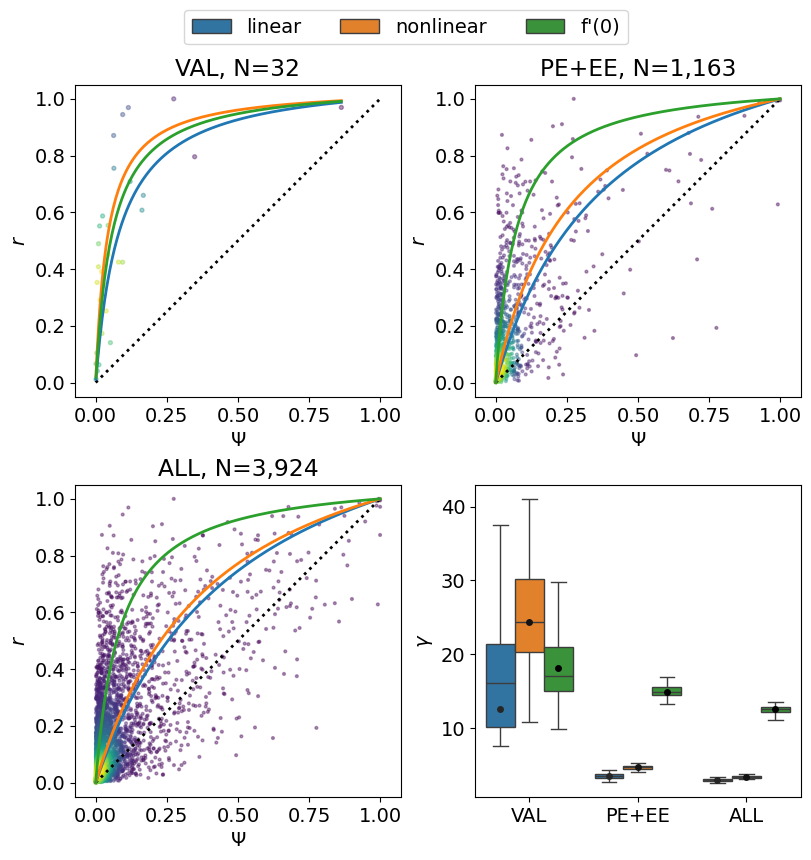

In [16]:
f, axes = plt.subplot_mosaic(
    """
    AB
    CD
    """,
    layout="constrained",
    figsize=(8,8),
    width_ratios=(1,1)
)

axes["B"].sharey(axes["A"])
axes["C"].sharey(axes["A"])

full_data = []
for (axname,ax),key,col in zip(axes.items(),names,cols):
    tmp = sets[sets[col]==1][['src','event_id']].merge(dkd) if col !='set0' else dkd.copy()
    z,idx = hf.plot2d(tmp.ctrl_psi,tmp.exp_psi)
    ax.scatter(tmp.ctrl_psi.iloc[idx],tmp.exp_psi.iloc[idx],c=z[idx],s=8 if col=='set1' else 4 ,alpha=0.4)
    ax.plot([0,1],[0,1],lw=2,ls=':',c='black')
    #t = f'{key}, N={len(tmp)}\n{int(100*np.mean((tmp.exp_psi-tmp.ctrl_psi)>0))}%>0'
    t = f'{key}, N={len(tmp):,}'
    resd,_ = hf.get_gamma(tmp,ax=ax,linear_thr=0.01,funcs=funcs)
    resd = pd.Series(resd)
    resd.name = key
    full_data.append(resd)
    ax.set_title(t)
    #ax.legend(loc='lower center',bbox_to_anchor=(0.5,1.1))
    ax.get_legend().remove()
    ax.axis('equal')
    ax.set_xlabel(r'$\Psi$')
    ax.set_ylabel(r'$r$')

ax = axes['D']

full_data = pd.concat(full_data,axis=1)
full_data['method'] = full_data.index
full_data = full_data.melt(id_vars='method',var_name='sets',value_name='gamma')

sns.boxplot(data=resdf2,y='gamma',hue='method',x='sets',ax=ax,showfliers=False)
handles, labels = ax.get_legend_handles_labels()
f.legend(handles, labels, loc='lower center',bbox_to_anchor=(0.5,1),ncol=3)

sns.stripplot(data=full_data,y='gamma',hue='method',x='sets',ax=ax, dodge=True,palette='dark:black')
ax.set_ylabel('$\gamma$')
ax.set_xlabel(None)
ax.get_legend().remove()
#ax.set_yscale('log')

In [17]:
f.savefig('./figures/Fig2.pdf',bbox_inches='tight')

## Figure 3

In [18]:
import mm
from importlib import reload
reload(mm)

<module 'mm' from 'C:\\Users\\zavil\\tcga_paper\\NMDeq\\nmd_psi\\mm.py'>

In [19]:
use = pd.read_csv('./nmd_inactivation_data/united_use_master_table.tsv',sep='\t')
ase = pd.read_csv('./nmd_inactivation_data/binASE_master_table.tsv',sep='\t')

use = use[(use.ctrl_psi!=0)&(use.exp_psi!=0)]
ase = ase[(ase.ctrl_psi!=0)&(ase.exp_psi!=0)]

In [20]:
def plot_dataset(exper,ctrl,ax=None,dropzeros=False, plot_borders=True, **kwargs):
    #tau=1, lambda_pi=0, lambda_sigma=0, n_init=10
    if ax is None:
        f,ax = plt.subplots()
    
    if dropzeros:
        exper = exper[(exper.ctrl_psi!=0)&(exper.exp_psi!=0)].copy()
        ctrl =  ctrl[(ctrl.ctrl_psi!=0)&(ctrl.exp_psi!=0)].copy()
    
    if (ctrl.shape[0]==0) or (exper.shape[0]==0):
        print(f'no data for {key}')
        return

    res,params,prob,other,results = mm.get_params_mixture(exper,ctrl,**kwargs)
    if res:
        mm.plot_model(exper,params,prob,ax=ax)
        print('prob',np.mean(prob>0.5))
    
        a0_hat, a1_hat, pi_hat, a_r_hat, b_r_hat, c_r_hat, a_nr_hat, b_nr_hat, c_nr_hat = params
        y = np.linspace(0,1,100)

        if plot_borders:
    
            sigma_r = mm.heteroskedastic_sigma(y, a_r_hat, b_r_hat, c_r_hat)
            sigma_nr = mm.heteroskedastic_sigma(y, a_nr_hat, b_nr_hat, c_nr_hat)
            sigma_r = np.maximum(sigma_r, 1e-3)
            sigma_nr = np.maximum(sigma_nr, 1e-3)
            curve_nr = mm.r2psi(y,a0_hat)
            curve_r = mm.r2psi(y,a1_hat)
    
            upper,lower = curve_r+sigma_r,curve_r-sigma_r
            upper,lower = np.clip(upper,0,1),np.clip(lower,0,1)
            ax.fill_betweenx(y,lower,upper,color='lightgrey',alpha=0.5)
            ax.plot(upper,y,c='grey',ls=':')
            ax.plot(lower,y,c='grey',ls=':')
            
            upper,lower = curve_nr+sigma_nr,curve_nr-sigma_nr
            upper,lower = np.clip(upper,0,1),np.clip(lower,0,1)
            ax.fill_betweenx(y,lower,upper,color='lightgrey',alpha=0.5)
            ax.plot(upper,y,c='grey',ls=':')
            ax.plot(lower,y,c='grey',ls=':')
    else:
        print(f'Model failed: {key}')
    return res,params,prob,other,results

### Mixture model plots for 3 sets of USEs in HeLa dKD

prob 0.96875


prob 0.7583834909716252


prob 0.6913863404689092
CPU times: total: 52.3 s
Wall time: 53.5 s


Text(0.02, 0.5, '$r$')

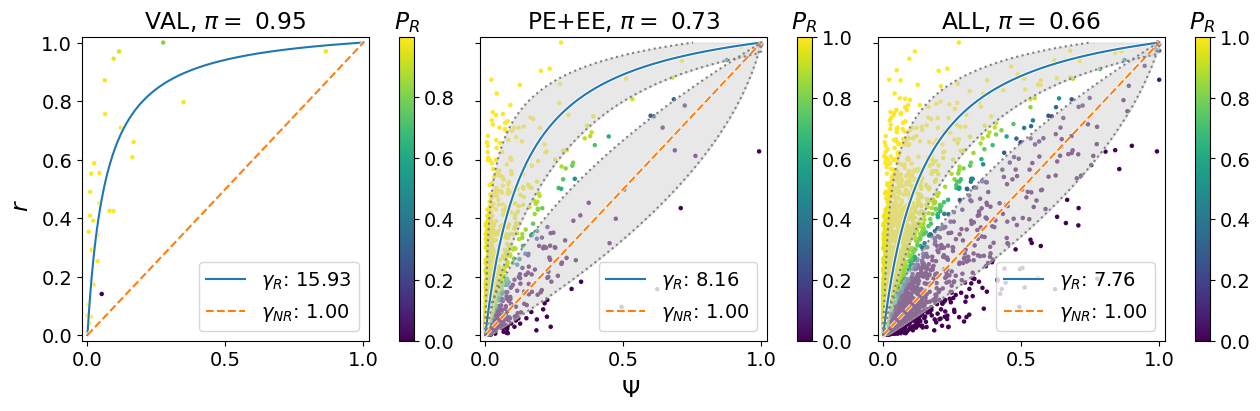

In [21]:
%%time
key = 'HeLa dKD'
cols = ['set1','set2','set3']
names = ['VAL', 'PE+EE', 'ALL']
#inits = [30,20,1]
inits = [30,30,30]

f,axes = plt.subplots(1,3,figsize=(12.5,4),constrained_layout=True,sharey=True)
for name,col,n_init,ax in zip(names,cols,inits,axes):

    exper = sets[sets[col]==1][['src','event_id']].merge(use) if col !='set0' else use.copy()
    exper = exper[exper.experiment==key].copy()
    ctrl = ase[ase.experiment==key].copy()

    plot_borders = False if name=='VAL' else True
    plot_dataset(exper,ctrl,n_init=n_init,ax=ax,plot_borders=plot_borders)
    t = ax.get_title()
    ax.set_title(f'{name}, {t}')
    ax.set_xlim(-0.02,1.02)
    ax.set_ylim(-0.02,1.02)
    
    xlab = ax.get_xlabel()
    ylab = ax.get_ylabel()
    ax.set_xlabel(None)
    ax.set_ylabel(None)
    #ax.axis('equal')
f.supxlabel(xlab)
f.supylabel(ylab)

In [22]:
#f.axes[3]._colorbar.remove()
ax = f.axes[0]
scatter = ax.collections[0]
scatter.set_clim(0, 1)

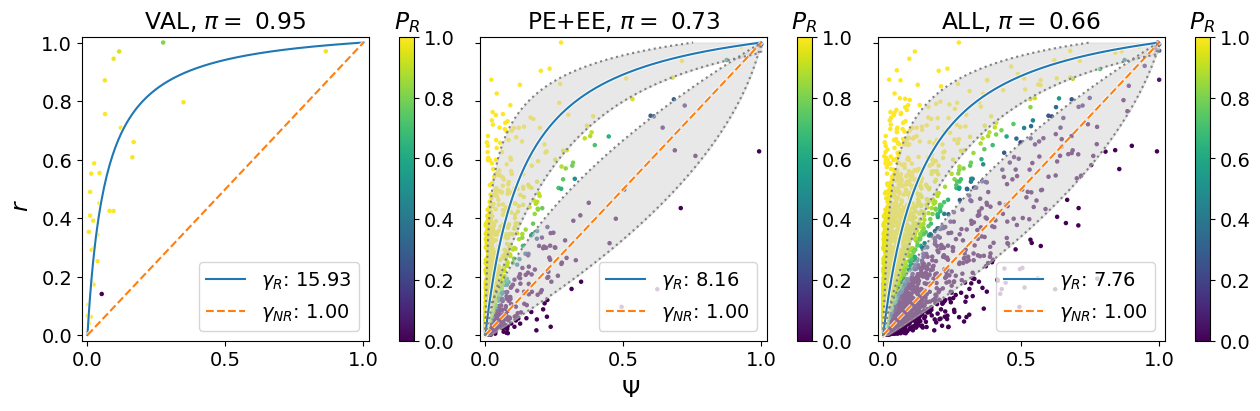

In [23]:
f

In [24]:
f.savefig('./figures/Fig3_mm_scatters.pdf',bbox_inches='tight')

### Other datasets (mm plots, stability of $\gamma_R$ and consistency between datasets)

<a id="sf3"></a>

#### Bootstrapping

In [25]:
good_data = ['HeLa CHX', 'HeLa SMG6 KD', 'HeLa UPF1 KD', 'HeLa dKD', 'HepG2 nucl/cyto', 'K562 nucl/cyto']
tmp = use[(use.exp_psi!=0)&(use.ctrl_psi!=0)&(use.experiment.isin(good_data))]
datasets = {key1: group for key1, group in tmp.groupby('experiment')}
kwargs = [{'ctrl':ase[(ase.experiment==key)&(ase.exp_psi!=0)&(ase.ctrl_psi!=0)],'n_init':10} for key in datasets]

In [26]:
'" "'.join(good_data)

'HeLa CHX" "HeLa SMG6 KD" "HeLa UPF1 KD" "HeLa dKD" "HepG2 nucl/cyto" "K562 nucl/cyto'

In [27]:
{key:len(value) for key,value in datasets.items()}

{'HeLa CHX': 329,
 'HeLa SMG6 KD': 3556,
 'HeLa UPF1 KD': 3552,
 'HeLa dKD': 3924,
 'HepG2 nucl/cyto': 2920,
 'K562 nucl/cyto': 3172}

In [28]:
[len(value['ctrl']) for value in kwargs]

[665, 2907, 2992, 3171, 2420, 2543]

In [29]:
n_workers = len(datasets)
n_workers

6

In [30]:
%%time
parameters = mm.parallel_bootstrap(datasets,n_workers=n_workers,bootstrap_kwargs=kwargs)

Finished: HeLa CHX


Finished: K562 nucl/cyto


Finished: HepG2 nucl/cyto


Finished: HeLa dKD


Finished: HeLa SMG6 KD


Finished: HeLa UPF1 KD


CPU times: total: 266 ms
Wall time: 9min 3s


In [31]:
res = []
for key,val in parameters.items():
    val['experiment'] = key
    res.append(val)
res = pd.concat(res)

In [32]:
res.to_csv('./nmd_inactivation_data/mixture_model_bootstrapping_anno.tsv',sep='\t',index=False)

In [33]:
res = pd.read_csv('./nmd_inactivation_data/mixture_model_bootstrapping_anno.tsv',sep='\t')

In [34]:
res.experiment.value_counts()

experiment
HeLa CHX           50
K562 nucl/cyto     50
HepG2 nucl/cyto    50
HeLa dKD           50
HeLa SMG6 KD       50
HeLa UPF1 KD       50
Name: count, dtype: int64

In [35]:
good_data = ['HeLa CHX', 'HeLa SMG6 KD', 'HeLa UPF1 KD', 'HeLa dKD', 'HepG2 nucl/cyto', 'K562 nucl/cyto']

prob 0.7173252279635258


prob 0.8000562429696289


prob 0.704954954954955


prob 0.6913863404689092


prob 0.7366438356164383


prob 0.6941992433795713
CPU times: total: 1min 33s
Wall time: 1min 34s


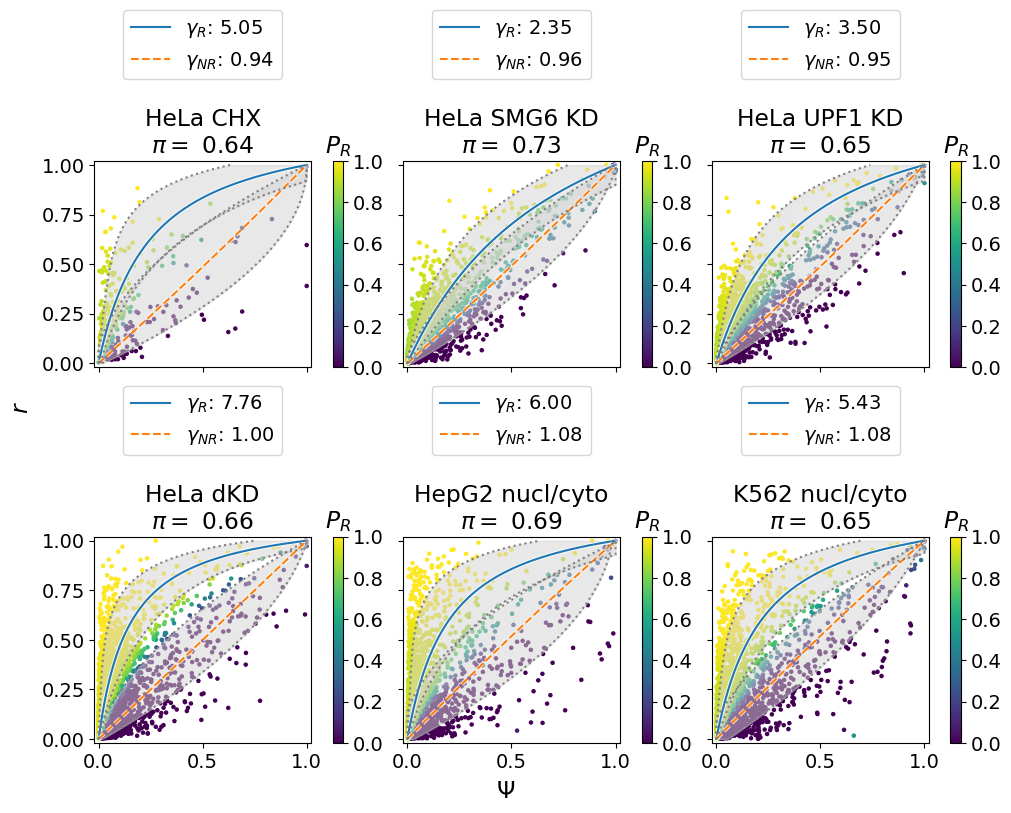

In [36]:
%%time
good_res = dict()

responder_df = []
n_init=20
f,ax = plt.subplots(2,3,figsize=(10,8),sharex=True,sharey=True,constrained_layout=True)
ax = ax.flatten()
for i,key in enumerate(good_data):
    ctrl = ase[ase.experiment==key]
    exper = use[use.experiment==key].copy()

    exper = exper[(exper.ctrl_psi!=0)&(exper.exp_psi!=0)]
    ctrl = ctrl[(ctrl.ctrl_psi!=0)&(ctrl.exp_psi!=0)]

    if (ctrl.shape[0]==0) or (exper.shape[0]==0):
        print(f'no data for {key}')
        continue
    try:
        lambda_sigma = 0
        success,params,prob,other,results = plot_dataset(exper,ctrl,n_init=n_init,ax=ax[i],lambda_sigma=lambda_sigma)
        exper['prob'] = prob
        responder_df.append(exper)
    except Exception as e:
        print(key)
        print(e)
        continue
    good_res[key] = params
    t = ax[i].get_title()
    ax[i].set_title(f'{key}\n{t}')
    ax[i].set_xlim(-0.02,1.02)
    ax[i].set_ylim(-0.02,1.02)
    xlab = ax[i].get_xlabel()
    ylab = ax[i].get_ylabel()
    ax[i].set_xlabel(None)
    ax[i].set_ylabel(None)
    ax[i].legend(loc='lower center', bbox_to_anchor=(0.5,1.35))
f.supxlabel(xlab)
f.supylabel(ylab)
for j in range(i+1,len(ax)):
    f.delaxes(ax[j])

responder_df = pd.concat(responder_df)
responder_df.to_csv('./nmd_inactivation_data/united_use_master_table_with_responder_prob_anno.tsv',sep='\t',index=False)

In [37]:
f.savefig('./figures/Fig3_mm_supplementary.pdf',bbox_inches='tight')

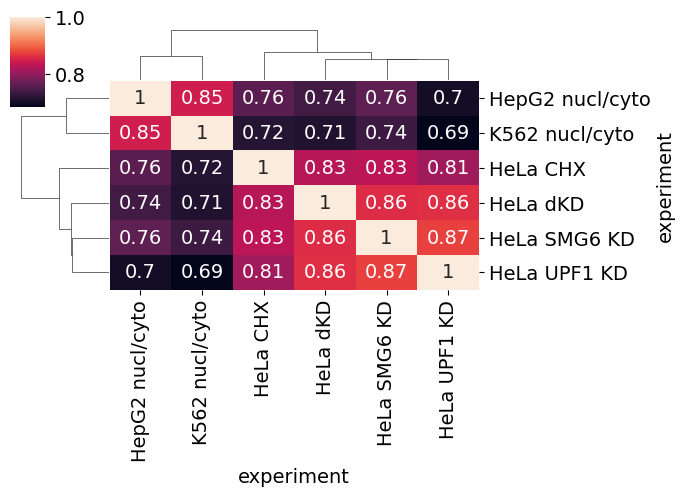

In [38]:
aa = pd.read_csv('./nmd_inactivation_data/united_use_master_table_with_responder_prob_anno.tsv',sep='\t')
responder_df = aa
responder_df['responder'] = np.where(responder_df.prob>0.5,1,0)

mat = responder_df.pivot(index=['src','event_id'],columns='experiment',values='responder')
#mat = mat[mat.notna().all(1)]

#aa = mat.isna().sum(1)
#bb = aa.value_counts()
#bb = bb.loc[sorted(bb.index)]
#ind = aa[aa<2].index
#mat - mat.loc[ind]

from sklearn.metrics import f1_score

def pairwise(x,y):
    idx = (np.isnan(x)|np.isnan(y))
    return f1_score(x[~idx],y[~idx])
mat = mat.corr(method=pairwise)

g = sns.clustermap(mat,annot=True,fmt='.2g',figsize=(7,5))

In [39]:
responder_df = pd.read_csv('./nmd_inactivation_data/united_use_master_table_with_responder_prob_anno.tsv',sep='\t')

In [40]:
responder_df['responder'] = np.where(responder_df.prob>0.5,1,0)

In [41]:
responder_df.groupby('experiment').responder.agg('mean')

experiment
HeLa CHX           0.717325
HeLa SMG6 KD       0.800056
HeLa UPF1 KD       0.704955
HeLa dKD           0.691386
HepG2 nucl/cyto    0.736644
K562 nucl/cyto     0.694199
Name: responder, dtype: float64

In [42]:
responder_df = responder_df[~responder_df.experiment.isin(['fractioning_A549','HeLa_SMG7_KD'])].copy()

In [43]:
responder_df.experiment = responder_df.experiment.str.replace('fractioning','frac')
res.experiment = res.experiment.str.replace('fractioning','frac')

In [44]:
responder_df.experiment.unique()

array(['HeLa CHX', 'HeLa SMG6 KD', 'HeLa UPF1 KD', 'HeLa dKD',
       'HepG2 nucl/cyto', 'K562 nucl/cyto'], dtype=object)

In [45]:
mat = responder_df.pivot(index=['src','event_id'],columns='experiment',values='responder')
#mat = mat[mat.notna().all(1)]

#aa = mat.isna().sum(1)
#bb = aa.value_counts()
#bb = bb.loc[sorted(bb.index)]
#ind = aa[aa<2].index
#mat - mat.loc[ind]

from sklearn.metrics import f1_score

def pairwise(x,y):
    idx = (np.isnan(x)|np.isnan(y))
    return f1_score(x[~idx],y[~idx])
mat = mat.corr(method=pairwise)

g = sns.clustermap(mat,annot=True,fmt='.2g',figsize=(6,5))
plt.close()

order = [i._text for i in g.ax_heatmap.get_xticklabels()]

f,ax = plt.subplots(1,3,figsize=(10,5),constrained_layout=True)


tmp = res[res.experiment.isin(order)].copy()
tmp.experiment = tmp.experiment.astype('category').cat.reorder_categories(order)
tmp = tmp.sort_values('experiment')
sns.boxplot(data=tmp,y='experiment',x='a1_hat',showfliers=False,ax=ax[0],color='lightgrey',linecolor='black')
ax[0].set_xlabel('$\gamma$')
ax[0].set_ylabel(None)

ax[0].axvline(1,ls=':',c='black')

t1 = ax[0].get_yticklabels()


corr = mat.loc[order,order].copy()
mask = np.zeros_like(corr, dtype=bool)
mask[np.triu_indices_from(mask)] = True
corr = corr.iloc[0:,:-1]
mask = mask[0:,:-1]
sns.heatmap(corr, mask=mask, annot=True, fmt='.2g', linewidths=.5, ax=ax[1],annot_kws={"size": 10})

ax[1].set_xticklabels(ax[1].get_xticklabels(),ha='right',rotation=45,rotation_mode='anchor')
#ax[1].set_xticklabels(ax[1].get_xticklabels(),ha='left',rotation=-45,rotation_mode='anchor')
ax[1].set_xlabel(None)
ax[1].set_ylabel(None)
ax[1].set_yticks([])

from matplotlib.ticker import MaxNLocator
ax[0].xaxis.set_major_locator(MaxNLocator(nbins=5))

t2 = ax[1].get_yticklabels()
f.axes[-1].set_title('F1')
plt.close()

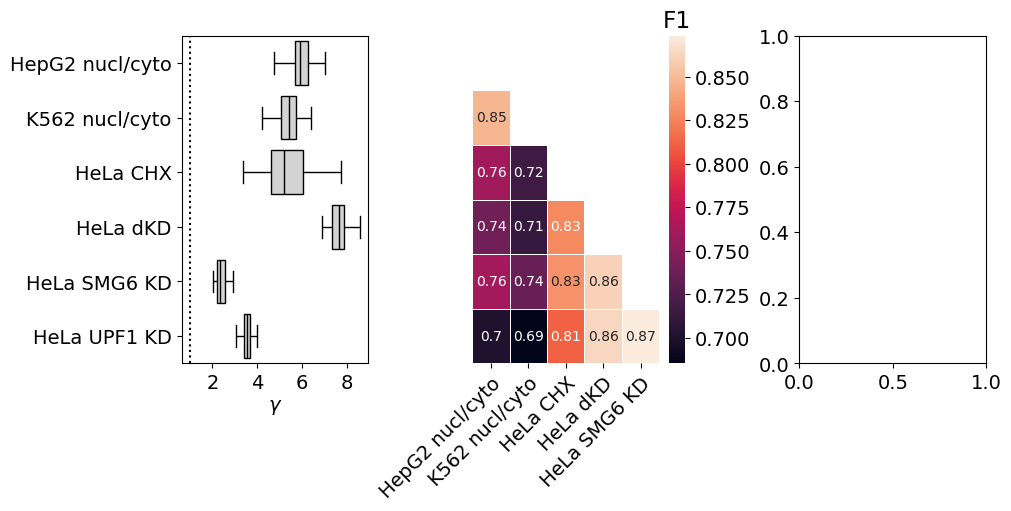

In [46]:
f

In [47]:
order

['HepG2 nucl/cyto',
 'K562 nucl/cyto',
 'HeLa CHX',
 'HeLa dKD',
 'HeLa SMG6 KD',
 'HeLa UPF1 KD']

### LogFC of R vs NR

In [48]:
responders = responder_df

In [49]:
lfc = []
for file in glob.glob('./nmd_inactivation_data/deseq_res/*tsv'):
    if not (("ripit" in file.lower()) or ("fractioning" in file.lower())):
        tmp = pd.read_csv(file,sep='\t',index_col=[0])
        name = 'chx' if 'CHX' in file else os.path.basename(file)[:-4]
        tmp['experiment'] = name
        tmp['gene_id'] = tmp.index
        lfc.append(tmp[['experiment','gene_id','log2FoldChange']])
ripit = pd.read_csv('./nmd_inactivation_data/deseq_res/ripit_gene_logFC.tsv',sep='\t').rename(columns={'logFC':'log2FoldChange'})
ripit = ripit[['experiment','gene_id','log2FoldChange']]
lfc.append(ripit)

frac = pd.read_csv('./nmd_inactivation_data/deseq_res/fractioning_logFC.tsv',sep='\t')
frac = frac[['experiment','gene_id','log2FoldChange']]
lfc.append(frac)

lfc = pd.concat(lfc)

#lfc.experiment = lfc.experiment.replace('hela_chx_24h','HeLa_chx')
#lfc.experiment = lfc.experiment.str.replace('fractioning','frac')

def replace(x):
    frac = 'nucl/cyto'
    xr = x.str.replace('_',' ').str.replace('fractioning',frac).str.replace('chx','CHX')
    cond = xr.str.contains(frac)
    xr.loc[cond] = xr.loc[cond].apply(lambda x: ' '.join(x.split(' ')[::-1]))
    return xr
lfc.experiment = replace(lfc.experiment)

In [50]:
lfc.experiment.unique()

array(['CHX', 'HeLa CHX', 'HeLa dKD', 'HeLa SMG6 KD', 'HeLa SMG7 KD',
       'HeLa UPF1 KD', 'RIPiT', 'HepG2 nucl/cyto', 'K562 nucl/cyto'],
      dtype=object)

In [51]:
catalog = pd.read_csv('./use_catalog/filtered_catalog.tsv',sep='\t')

In [52]:
cat = catalog[['gene_id','src','event_id']].drop_duplicates()

In [53]:
condition = (responders.prob>0.5)&(responders.exp_psi>0.05)
responders['responder'] = np.where(condition,'R','NR')

In [54]:
aa = responders
resp = cat.merge(aa).sort_values('responder',ascending=False)[['gene_id','experiment','responder']].drop_duplicates()

In [55]:
resp.experiment.unique()

array(['HeLa SMG6 KD', 'HeLa dKD', 'K562 nucl/cyto', 'HepG2 nucl/cyto',
       'HeLa CHX', 'HeLa UPF1 KD'], dtype=object)

In [56]:
resp = resp.merge(lfc)

In [57]:
resp[['experiment','responder']].value_counts(sort=False)

experiment       responder
HeLa CHX         NR            121
                 R             177
HeLa SMG6 KD     NR           1605
                 R            1255
HeLa UPF1 KD     NR           1621
                 R            1217
HeLa dKD         NR           1532
                 R            1608
HepG2 nucl/cyto  NR           1177
                 R            1117
K562 nucl/cyto   NR           1335
                 R            1187
Name: count, dtype: int64

In [58]:
resp.experiment = resp.experiment.astype('category').cat.reorder_categories(order)
resp = resp.sort_values(['experiment','responder'],ascending=[True,False])

In [59]:
f.axes[2].clear()

In [60]:
sns.boxplot(data=resp,y='experiment',x='log2FoldChange',hue='responder',showfliers=False,ax=ax[2])
ax[2].set_yticks([])
ax[2].set_ylabel(None)
ax[2].legend(title=None,loc='lower center', bbox_to_anchor=(0.5,1),ncol=2)

ax[2].axvline(0,ls=':',c='black')


from statannotations.Annotator import Annotator

pairs = [((i,'R'),(i,'NR')) for i in order]
annotator = Annotator(
    ax[2],
    pairs,
    data=resp,
    y='experiment',
    x='log2FoldChange',
    hue='responder',
    orient="h"
)

annotator.configure(
    test="Mann-Whitney", 
    text_format="star",     
    loc="inside",           
    comparisons_correction="bonferroni"
)

annotator.apply_and_annotate()

p-value annotation legend:
      ns: 5.00e-02 < p <= 1.00e+00
       *: 1.00e-02 < p <= 5.00e-02
      **: 1.00e-03 < p <= 1.00e-02
     ***: 1.00e-04 < p <= 1.00e-03
    ****: p <= 1.00e-04

K562 nucl/cyto_R vs. K562 nucl/cyto_NR: Mann-Whitney-Wilcoxon test two-sided with Bonferroni correction, P_val:7.643e-30 U_stat=1.002e+06
HepG2 nucl/cyto_R vs. HepG2 nucl/cyto_NR: Mann-Whitney-Wilcoxon test two-sided with Bonferroni correction, P_val:7.396e-31 U_stat=8.429e+05
HeLa CHX_R vs. HeLa CHX_NR: Mann-Whitney-Wilcoxon test two-sided with Bonferroni correction, P_val:1.282e-02 U_stat=1.295e+04
HeLa dKD_R vs. HeLa dKD_NR: Mann-Whitney-Wilcoxon test two-sided with Bonferroni correction, P_val:6.501e-04 U_stat=1.330e+06
HeLa SMG6 KD_R vs. HeLa SMG6 KD_NR: Mann-Whitney-Wilcoxon test two-sided with Bonferroni correction, P_val:1.410e-05 U_stat=1.111e+06
HeLa UPF1 KD_R vs. HeLa UPF1 KD_NR: Mann-Whitney-Wilcoxon test two-sided with Bonferroni correction, P_val:1.000e+00 U_stat=1.005e+06


(<Axes: xlabel='log2FoldChange'>,
  <statannotations.Annotation.Annotation at 0x1be2cddcf70>])

<Figure size 640x480 with 0 Axes>

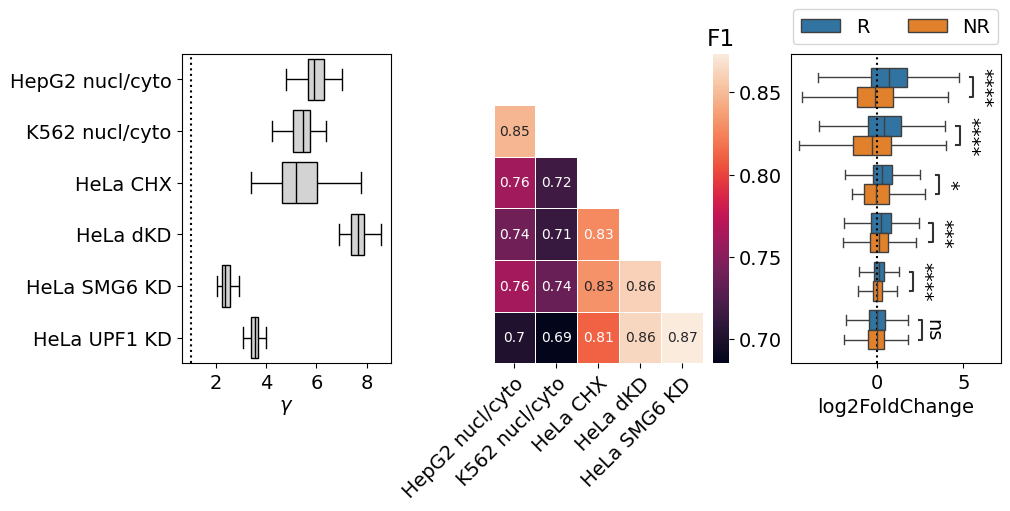

In [61]:
f

In [62]:
ax = f.axes[0]
pos = ax.get_position()
pos.x0 = 0.1
pos.x1 = 0.34
ax.set_position(pos)
f.axes[2].set_xlabel(r'$\log_2$FC')

Text(0.5, 113.34238349156125, '$\\log_2$FC')

In [63]:
pos.x1

0.34

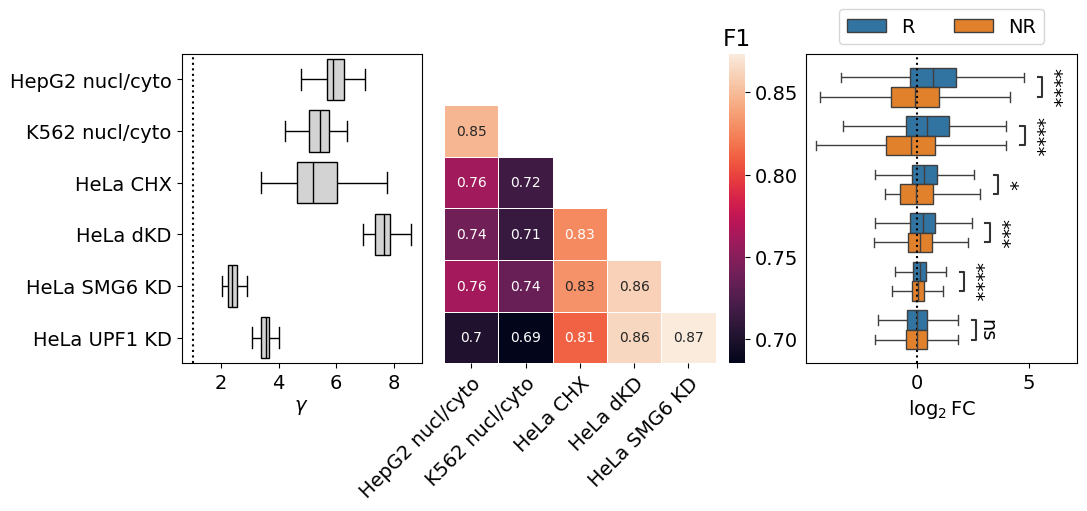

In [64]:
f

In [65]:
f.savefig('./figures/Fig3_mm_stability_consistency_and_logFC.pdf',bbox_inches='tight')

In [66]:
aa = responders[responders.experiment=='HeLa_dKD'][['src','event_id','responder']].drop_duplicates()
masha = aa.merge(catalog)
masha.to_csv('C:/Users/zavil/Downloads/responders.tsv',sep='\t',index=False)

### PhyloP and RiboSeq

In [67]:
phylop = pd.read_csv('C:/Users/zavil/Downloads/Telegram Desktop/PE.up_down_regions_periodicity.539events.csv')
phylop = phylop[(phylop.cons == "phylop30_pos")&(phylop.region == "up")].copy()
phylop.responder = phylop.responder.map({True:'R',False:'NR'})

In [68]:
tmp = phylop.copy()
f,(ax,ax2) = plt.subplots(1,2,figsize=(10,1.5),constrained_layout=True,sharey=True)
sns.boxplot(data=tmp,y='responder',x='dcons',hue='responder',showfliers=False,ax=ax)
ax.set_xlabel('Coding potential')
ax.set_ylabel(None)


from statannotations.Annotator import Annotator

pairs = [('R','NR')]
annotator = Annotator(
    ax,
    pairs,
    data=tmp,
    y='responder',
    x='dcons',
    orient="h"
)

annotator.configure(
    test="Mann-Whitney", 
    text_format="star",     
    loc="inside",           
#    comparisons_correction="bonferroni"
)

annotator.apply_and_annotate()
plt.close()

p-value annotation legend:
      ns: 5.00e-02 < p <= 1.00e+00
       *: 1.00e-02 < p <= 5.00e-02
      **: 1.00e-03 < p <= 1.00e-02
     ***: 1.00e-04 < p <= 1.00e-03
    ****: p <= 1.00e-04

R vs. NR: Mann-Whitney-Wilcoxon test two-sided, P_val:3.749e-02 U_stat=2.580e+04


In [69]:
#riboseq = 'C:/Users/zavil/Downloads/Telegram Desktop/PE.up_down_regions_w_ribosome_profiling_EMTAB.539events.csv'
riboseq = 'C:/Users/zavil/Downloads/Telegram Desktop/PE_up_down_regions_w_ribosome_profiling_EMTAB_cov_matched_subset.csv'

riboseq = pd.read_csv(riboseq,usecols=['src','event_id','responder','cov_whole','cov_up','cov_down',
                                       'width_whole','width_up','width_down','readth_fr','matching_group'])
riboseq.responder = riboseq.responder.map({True:'R',False:'NR'})

p-value annotation legend:
      ns: 5.00e-02 < p <= 1.00e+00
       *: 1.00e-02 < p <= 5.00e-02
      **: 1.00e-03 < p <= 1.00e-02
     ***: 1.00e-04 < p <= 1.00e-03
    ****: p <= 1.00e-04

R vs. NR: Mann-Whitney-Wilcoxon test two-sided, P_val:1.046e-02 U_stat=4.040e+03


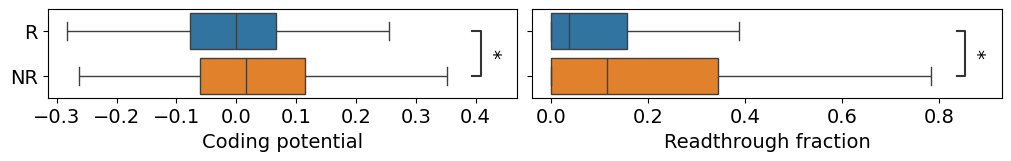

<Figure size 640x480 with 0 Axes>

In [70]:
tmp = riboseq[(riboseq.width_up>10)&(riboseq.width_down>5)&(riboseq.cov_up>0.1)]

sns.boxplot(data=tmp,y='responder',x='readth_fr',hue='responder',showfliers=False,ax=ax2)

pairs = [('R','NR')]
annotator = Annotator(
    ax2,
    pairs,
    data=tmp,
    y='responder',
    x='readth_fr',
    orient="h"
)

annotator.configure(
    test="Mann-Whitney", 
    text_format="star",     
    loc="inside",           
#    comparisons_correction="bonferroni"
)

annotator.apply_and_annotate()


ax2.set_xlabel('Readthrough fraction')
ax2.set_ylabel(None)
f

In [71]:
f.savefig('./figures/Fig3_phylop_and_riboseq.pdf',bbox_inches='tight')

## Figure 4

In [72]:
GAMMA = 'gamma_emp'

In [73]:
responders = pd.read_csv('./nmd_inactivation_data/united_use_master_table_with_responder_prob_anno.tsv',sep='\t')
condition = (responders.exp_psi>0.05)&(responders.prob>0.5)
responders['responder'] = np.where(condition,'R','NR')

In [74]:
gamma = pd.read_csv('./nmd_inactivation_data/united_use_master_table.tsv',sep='\t')
gamma = gamma[(gamma.ctrl_psi!=0)&(gamma.exp_psi!=0)].copy()
gamma['gamma_emp'] = hf.psir2gamma(gamma.ctrl_psi,gamma.exp_psi)

<Axes: xlabel='gamma_emp', ylabel='Density'>

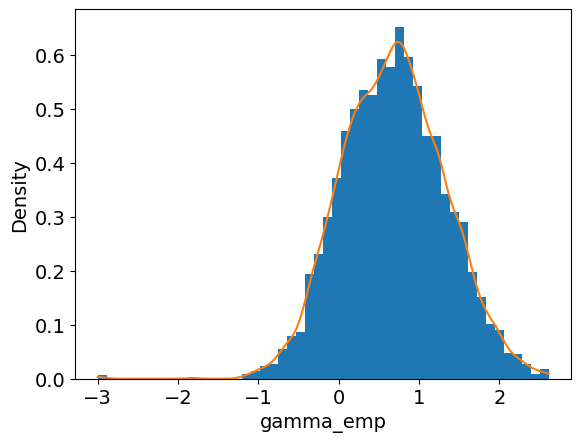

In [75]:
f,ax = plt.subplots()
aa = gamma[(gamma.experiment=='HeLa dKD')&(np.isfinite(gamma[GAMMA]))][GAMMA]
#aa = aa[aa<20]
aa = np.log10(aa+0.001)
plt.hist(aa,density=True,bins=50)
sns.kdeplot(aa,bw_adjust=0.8,cut=0,ax=ax)
#plt.axvline(0.38)
#plt.axvline(point,c='red')
#plt.axvline(0.8)

In [76]:
resp = gamma.merge(responders)

In [77]:
resp.experiment.unique()

array(['HepG2 nucl/cyto', 'K562 nucl/cyto', 'HeLa CHX', 'HeLa SMG6 KD',
       'HeLa UPF1 KD', 'HeLa dKD'], dtype=object)

In [78]:
resp = resp[(resp.ctrl_psi!=0)&(resp.exp_psi!=0)]

#### Psi ~ expr corcoef in GTEx

In [79]:
catalog = pd.read_csv('./use_catalog/filtered_catalog.tsv',sep='\t')
cat = catalog[['gene_id','src','event_id']].drop_duplicates()

In [80]:
from scipy.stats import spearmanr

In [81]:
%%time
import pickle
with open('psi_expression_gtex.pkl', "rb") as f:
    psi = pickle.load(f)

CPU times: total: 4.34 s
Wall time: 4.48 s


In [82]:
catalog[['src','event_id']].drop_duplicates().src.value_counts()

src
ensembl    10822
chess       3728
Name: count, dtype: int64

In [83]:
psi['psi'] = psi.num/psi.denom

In [84]:
%%time

res = []
i=0

import time
start_time = time.time()
for key,tmp in psi[(psi.psi!=0)&(psi.expr.notna())].groupby(['src','event_id']):
    i+=1
    if i%10000==1:
        print(f'Done {i}',time.time()-start_time)
    if len(tmp)<40:
        continue
    if np.std(tmp.psi)==0:
        continue
    r,p = spearmanr(tmp.expr,tmp.psi,nan_policy='omit')
    res.append([*key,r,p])
res = pd.DataFrame(res,columns=['src','event_id','r','p'])
!mkdir gtex
res.to_csv('./gtex/cor_expr_vs_psi_gtex_all_tissues_nozero.csv')

<timed exec>:6: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.


Done 1 4.972150564193726


Done 10001 90.7793321609497


CPU times: total: 1min 37s
Wall time: 1min 39s


In [85]:
res = []

In [86]:
psi['dthr'] = (psi.denom>15).astype(int)
psi['psi'] = psi.num/psi.denom
meanpsi = psi.groupby(['src','event_id'],observed=True).agg({'psi':['mean','std'],'dthr':'mean'})
meanpsi.columns = ['psi','psi_std','dthr']
meanpsi = meanpsi.reset_index()

meanpsi['cv'] = meanpsi.psi_std/meanpsi.psi

In [87]:
coefs = pd.read_csv('./gtex/cor_expr_vs_psi_gtex_all_tissues_nozero.csv',index_col=[0])

In [88]:
df = coefs.merge(resp).merge(meanpsi)

In [89]:
pthr = 1 
stdthr = 0
cvthr = 1 
psithr = 0.01 
dthr = 0.6

formula = 'r ~ psi_z + responder'
formula2 = 'r ~ psi_z + gamma_i_z'
tmp = df[(df.experiment=='HeLa dKD')&(df.p<pthr)&(df.psi_std>stdthr)&(df.cv>cvthr)&(df.psi>psithr)&(df.dthr>dthr)].copy()
tmp['gamma_i_z'] = np.log(tmp[GAMMA])
tmp.gamma_i_z = (tmp.gamma_i_z-np.mean(tmp.gamma_i_z))/np.std(tmp.gamma_i_z)
tmp['psi_z'] = (tmp.psi-np.mean(tmp.psi))/np.std(tmp.psi)
print(tmp.shape)
hf.get_ols_res(formula,tmp)

(1503, 19)


,coef,std_err,t,p_value,ci_lower,ci_upper,adj_R,F_pval
Intercept,-0.347430,0.008701,-39.930298,3.896032e-238,-0.364497,-0.330362,0.046538,1.105771e-16
responder[T.R],-0.031528,0.011086,-2.843890,4.517093e-03,-0.053274,-0.009782,0.046538,1.105771e-16
psi_z,0.044550,0.005392,8.262821,3.091816e-16,0.033974,0.055126,0.046538,1.105771e-16


In [90]:
hf.get_ols_res(formula2,tmp)

,coef,std_err,t,p_value,ci_lower,ci_upper,adj_R,F_pval
Intercept,-0.366854,0.005384,-68.139341,0.000000e+00,-0.377415,-0.356293,0.048753,1.931549e-17
psi_z,0.042635,0.005403,7.890621,5.753672e-15,0.032037,0.053234,0.048753,1.931549e-17
gamma_i_z,-0.018403,0.005403,-3.405910,6.768565e-04,-0.029002,-0.007804,0.048753,1.931549e-17


In [91]:
catalog = pd.read_csv('./use_catalog/filtered_catalog.tsv',sep='\t')
cat = catalog[['src','event_id','gene_id','event_type']].drop_duplicates().copy()

In [92]:
tmp = tmp.merge(cat)

In [93]:
tmp['psi_bin'] = pd.qcut(tmp.psi,5)
tmp['coef_sign'] = (tmp.r>0).map({True:1,False:-1})

In [94]:
tmp[GAMMA].describe()

count    1503.000000
mean       15.167710
std        31.613795
min         0.013609
25%         2.098804
50%         5.567442
75%        15.069467
max       356.818182
Name: gamma_emp, dtype: float64

In [95]:
def p2star(p):
    thrs = [0.0001,0.001,0.01,0.05,0.1]
    star = ['****','***','**','*','·']
    for t,s in zip(thrs,star):
        if p<t:
            return s
    return ""

def add_N(col,sep='\n',brac=True):
    d = col.value_counts()
    if brac:
        d = {k:f'{k}{sep}$(n={v})$'  for k,v in d.items()}
    else:
        d = {k:f'{k}{sep}$n={v}$'  for k,v in d.items()}
    return col.map(d)

In [96]:
tmp.responder.value_counts()

responder
R     926
NR    577
Name: count, dtype: int64

p-value annotation legend:
      ns: 5.00e-02 < p <= 1.00e+00
       *: 1.00e-02 < p <= 5.00e-02
      **: 1.00e-03 < p <= 1.00e-02
     ***: 1.00e-04 < p <= 1.00e-03
    ****: p <= 1.00e-04

R
$n=926$ vs. NR
$n=577$: Mann-Whitney-Wilcoxon test two-sided, P_val:1.625e-02 U_stat=2.475e+05


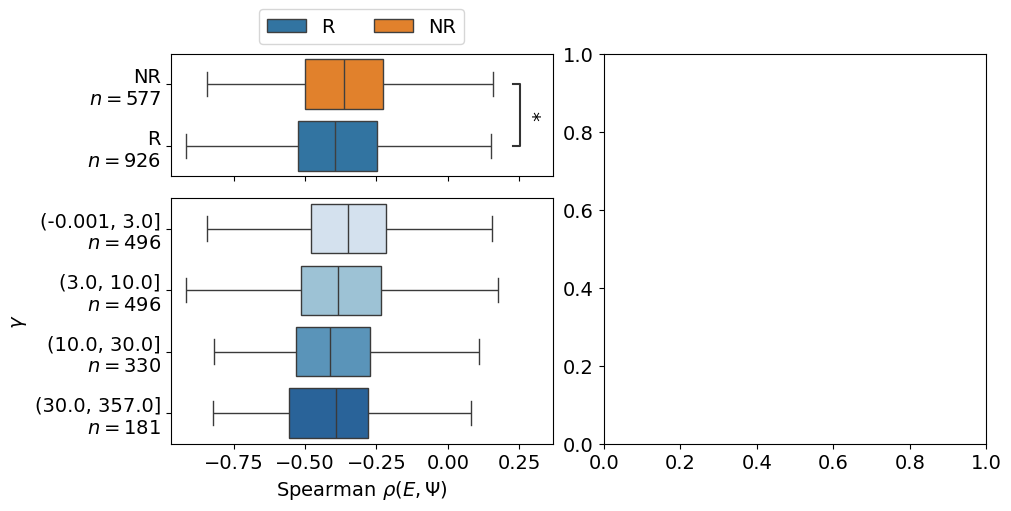

In [97]:
tmp2 = tmp.copy()

bins = [0,3,10,30,int(max(tmp2[GAMMA]))+1]

if GAMMA == 'gamma_i':
    tmp2['gamma_bin'] = pd.cut(
        tmp2[GAMMA],
        bins
    )
else:
    tmp2['gamma_bin'] = pd.cut(
        tmp2[GAMMA],
        bins,
        include_lowest=True
    )

tmp2.responder = add_N(tmp2.responder, sep='\n', brac=False)
tmp2.gamma_bin = add_N(tmp2.gamma_bin, sep='\n', brac=False)
tmp2 = tmp2.sort_values('responder', ascending=False)


def jitter(ax, width):
    for l in ax.lines:
        if l.get_marker() != '':
            xs = l.get_xdata()
            xs += np.random.uniform(-width, width, len(xs))
            l.set_xdata(xs)


flierprops = {'marker': '.', 'ms': 3}
showfliers = False


f, axes = plt.subplot_mosaic(
    """
    AC
    BC
    """,
    layout="constrained",
    figsize=(10,5),
    width_ratios=(1,1),
    height_ratios=(1, 2),
)

ax1, ax2 = axes['A'], axes['B']

ax2.sharex(ax1)
ax1.tick_params(labelbottom=False)

# ------------------------
# responder comparison
# ------------------------
sns.boxplot(
    data=tmp2,
    x='r',
    y='responder',
    ax=ax1,
    hue='responder',
    legend=True,
    flierprops=flierprops,
    showfliers=showfliers,
    orient='h'
)

# ------------------------
# gamma bins
# ------------------------
sns.boxplot(
    data=tmp2,
    x='r',
    y='gamma_bin',
    hue='gamma_bin',
    palette='Blues',
    flierprops=flierprops,
    showfliers=showfliers,
    ax=ax2,
    legend=False,
    orient='h'
)
h,l = ax1.get_legend_handles_labels()

ax1.legend(handles=h,labels=[i.split('\n')[0] for i in l],ncol=2,loc='lower center',bbox_to_anchor=(0.5,1))

for ax in [ax1,ax2]:
    ax.set_xlabel(None)
    jitter(ax, 0.05)

ax2.set_xlabel(r'Spearman $\rho(E,\Psi)$')

# ========================
# Statistical annotation
# ========================

from statannotations.Annotator import Annotator

pairs = [tuple(tmp2.responder.unique())]

annotator = Annotator(
    ax1,
    pairs,
    data=tmp2,
    y="responder",
    x="r",
    orient='h'
)

annotator.configure(
    test="Mann-Whitney",
    text_format="star",
    loc="inside"
)

annotator.apply_and_annotate()

ax1.set_ylabel(None)
ax2.set_ylabel(r'$\gamma$')

# если нужен прежний порядок категорий
ax1.invert_yaxis()

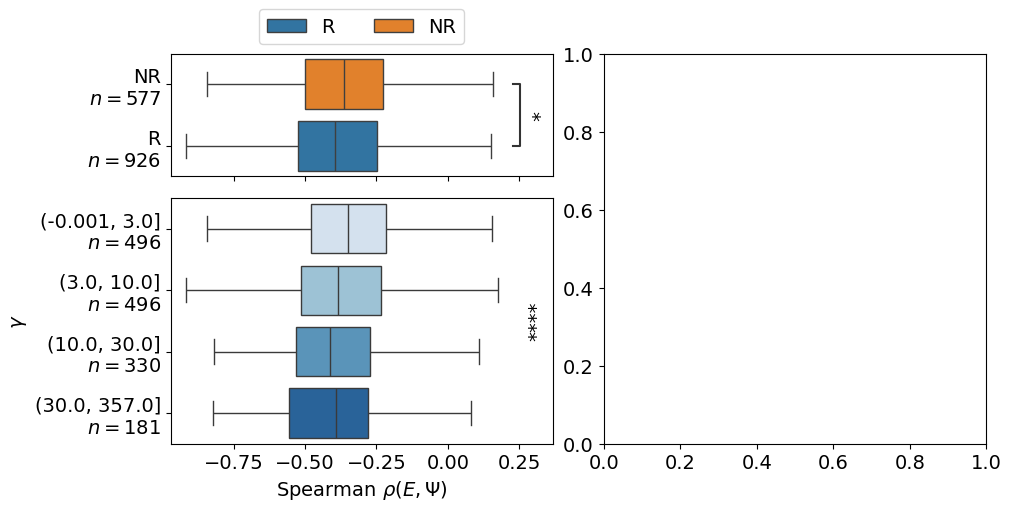

In [98]:
formula = 'r ~ gamma_i_z'
df = hf.get_ols_res(formula, tmp2)

p = df.loc['gamma_i_z', 'p_value']
star = p2star(p)

star_text = ax1.texts[0]

x, y = star_text.get_position()
x_disp, y_disp = star_text.get_transform().transform((x, y))
x2, y2 = ax2.transData.inverted().transform((x_disp, y_disp))

import matplotlib.transforms as transforms

trans2 = transforms.blended_transform_factory(ax2.transData,ax2.transAxes)

ax2.text(x2,0.5,star,ha='left',va='center',rotation=90,transform=trans2)
f

#### logFC vs gamma in NMDKD

In [99]:
lfc = []
for file in glob.glob('./nmd_inactivation_data/deseq_res/*tsv'):
    if not (("ripit" in file.lower()) or ("fractioning" in file.lower())):
        tmp = pd.read_csv(file,sep='\t',index_col=[0])
        name = 'chx' if 'CHX' in file else os.path.basename(file)[:-4]
        tmp['experiment'] = name
        tmp['gene_id'] = tmp.index
        lfc.append(tmp[['experiment','gene_id','log2FoldChange']])
ripit = pd.read_csv('./nmd_inactivation_data/deseq_res/ripit_gene_logFC.tsv',sep='\t').rename(columns={'logFC':'log2FoldChange'})
ripit = ripit[['experiment','gene_id','log2FoldChange']]
lfc.append(ripit)

frac = pd.read_csv('./nmd_inactivation_data/deseq_res/fractioning_logFC.tsv',sep='\t')
frac = frac[['experiment','gene_id','log2FoldChange']]
lfc.append(frac)

lfc = pd.concat(lfc)

#lfc.experiment = lfc.experiment.replace('hela_chx_24h','HeLa_chx')
#lfc.experiment = lfc.experiment.str.replace('fractioning','frac')
lfc.experiment = replace(lfc.experiment)

In [100]:
df = resp.merge(cat).merge(lfc).sort_values(GAMMA,ascending=False).drop_duplicates(['experiment','gene_id'])

In [101]:
lfc.experiment.unique()

array(['CHX', 'HeLa CHX', 'HeLa dKD', 'HeLa SMG6 KD', 'HeLa SMG7 KD',
       'HeLa UPF1 KD', 'RIPiT', 'HepG2 nucl/cyto', 'K562 nucl/cyto'],
      dtype=object)

In [102]:
resp.experiment.unique()

array(['HepG2 nucl/cyto', 'K562 nucl/cyto', 'HeLa CHX', 'HeLa SMG6 KD',
       'HeLa UPF1 KD', 'HeLa dKD'], dtype=object)

In [103]:
fill = max(df.loc[df[GAMMA]!=np.inf,GAMMA])
df[GAMMA] = np.where(df[GAMMA]==np.inf,fill,df[GAMMA])

In [104]:
bins = [0,3,10,30,int(max(df[GAMMA]))+1]
df['gamma_bin'] = pd.cut(df[GAMMA],bins)

In [105]:
axes['C'].clear()

In [106]:
aa = df[(df.exp_psi>0.01)&(df.ctrl_psi>0.01)].groupby('experiment').gamma_bin.value_counts().reset_index()
aa.pivot(index='experiment',columns='gamma_bin').fillna(0).astype(int)

count                           
gamma_bin       (0, 3] (3, 10] (10, 30] (30, 813]
experiment                                       
HeLa CHX           126      75       37        13
HeLa SMG6 KD      1184     466       41         7
HeLa UPF1 KD      1008     576       86         6
HeLa dKD           701     625      332       114
HepG2 nucl/cyto    588     405      199       125
K562 nucl/cyto     785     478      230        70

In [107]:
resp.experiment.unique()

array(['HepG2 nucl/cyto', 'K562 nucl/cyto', 'HeLa CHX', 'HeLa SMG6 KD',
       'HeLa UPF1 KD', 'HeLa dKD'], dtype=object)

In [108]:
order = ['HepG2 nucl/cyto','K562 nucl/cyto','HeLa CHX','HeLa dKD','HeLa SMG6 KD','HeLa UPF1 KD']
combs = list(combinations(df.gamma_bin.unique(),2))
pairs = [((i,l1),(i,l2)) for l1,l2 in combs for i in order]

In [109]:
df[df.gamma_bin.isna()]

,src,event_id,experiment,ctrl_psi,exp_psi,ctrl_denom,exp_denom,file,gamma_emp,prob,responder,gene_id,event_type,log2FoldChange,gamma_bin
6158,ensembl,ENSG00000132478_0,HeLa CHX,1.0,0.389749,20.250000,58.250000,hela_chx,0.0,4.170781e-13,NR,ENSG00000132478,alt_end,1.498514,NaN
14022,chess,ENSG00000158286_1,HeLa dKD,1.0,0.872727,34.000000,36.666667,hela_kd,0.0,7.570791e-02,NR,ENSG00000158286,IR,-0.546789,NaN
6097,ensembl,ENSG00000101901_1,HeLa CHX,1.0,0.596296,16.500000,54.500000,hela_chx,0.0,7.807811e-06,NR,ENSG00000101901,A5SS,1.073256,NaN
6906,chess,ENSG00000158286_1,HeLa SMG6 KD,1.0,0.977528,34.000000,44.500000,hela_kd,0.0,2.912337e-01,NR,ENSG00000158286,IR,0.272852,NaN
10464,chess,ENSG00000164975_5,HeLa UPF1 KD,1.0,0.996114,135.166667,257.333333,hela_kd,0.0,5.511647e-02,NR,ENSG00000164975,PE|PE2|alt_start,0.886804,NaN
14337,chess,ENSG00000204681_0,HeLa dKD,1.0,0.994536,19.000000,91.500000,hela_kd,0.0,6.670997e-02,NR,ENSG00000204681,EE,1.444695,NaN
10397,chess,ENSG00000158286_1,HeLa UPF1 KD,1.0,0.908815,34.000000,54.833333,hela_kd,0.0,5.076553e-01,R,ENSG00000158286,IR,0.661411,NaN


In [110]:
import matplotlib.transforms as transforms
if GAMMA == 'gamma_i':
    df['gamma_bin'] = pd.cut(df[GAMMA],bins)
    #df['gamma_bin'] = pd.qcut(df[GAMMA],4)
else:
    df['gamma_bin'] = pd.cut(df[GAMMA],bins)

df = df[(df.exp_psi>0.01)&(df.ctrl_psi>0.01)&(df.exp_psi<0.99)&(df.ctrl_psi<0.99)].copy()
tmp = df.copy()
filt = tmp.groupby(['experiment','gamma_bin'],sort=False,observed=True).size()
filt = filt[filt>20].reset_index().merge(tmp)

filt.experiment = filt.experiment.astype('category').cat.reorder_categories(order)
filt.sort_values('experiment')

#f,ax = plt.subplots()
ax = axes['C']
sns.boxplot(data=filt,y='experiment',x='log2FoldChange',hue='gamma_bin',showfliers=False,ax=ax,palette='Blues')
#sns.violinplot(data=filt,y='experiment',x='log2FoldChange',hue='gamma_bin',ax=ax,palette='Blues')
ax.legend(title=r'$\gamma$',loc='lower center', bbox_to_anchor=(0.5,1),ncol=2)
#ax.legend(title=r'$\gamma$')
ax.set_ylabel(None)

ax.axvline(0,ls=':',c='black')

formula = 'r ~ gamma_i_z'
for l in ax.get_yticklabels():
    formula = 'log2FoldChange ~ gamma_i_z'
    key,pos = l._text,l._y
    tmp = df[df.experiment==key].copy()
    tmp['gamma_i_z'] = np.log10(tmp[GAMMA])
    tmp.gamma_i_z = (tmp.gamma_i_z-np.mean(tmp.gamma_i_z))/np.std(tmp.gamma_i_z)
    aa = hf.get_ols_res(formula, tmp)
    p = aa.loc['gamma_i_z', 'p_value']
    star = p2star(p)
    trans = transforms.blended_transform_factory(ax.transAxes,ax.transData)
    ax.text(1.01,pos,star,ha='left',va='center',transform=trans,rotation=90)


In [111]:
f.axes[1].set_xlabel(r'$\log_2$FC')

Text(0.5, 0, '$\\log_2$FC')

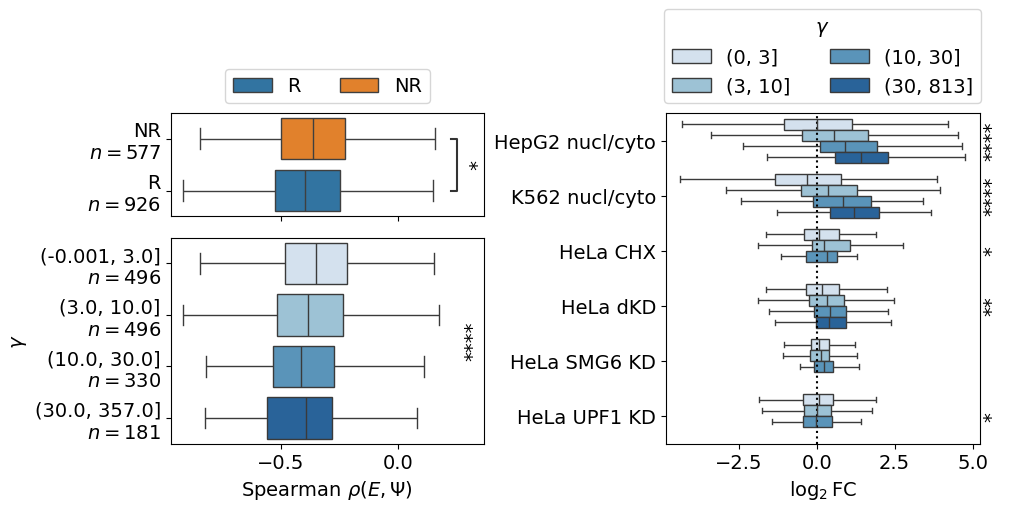

In [112]:
f

In [113]:
f.savefig('./figures/Fig4_gtex_and_logFC_in_NMDKD.pdf',bbox_inches='tight')

## Figure 5 (Individual figures examples)

In [114]:
d = {'RIC8B':'ENSG00000111785_2','PSPC1':'ENSG00000121390_0',
     'NFAT5':'ENSG00000102908_0','U2SURP':'ENSG00000163714_0',
     'RAB5IF':'ENSG00000101084_0','NCSTN':'ENSG00000162736_3'}

df = pd.DataFrame({'gene_name':d.keys(),'event_id':d.values(),'src':'ensembl'})

cols = ['gene_id','src','event_id','nmd_id_list','coding_id_list']
aa = catalog[catalog.transcript_biotype=='nonsense_mediated_decay'][cols+['long_id']]
aa = aa.merge(df)
aa['long_id'] = aa.long_id.apply(lambda x: set() if 'chr_' in x else set([int(i) for i in x.split('_')[1:-1]]))
aa = aa.groupby(cols,as_index=False).long_id.agg(lambda x: set.union(*x))
aa['vmin'] = aa.long_id.map(min)
aa['vmax'] = aa.long_id.map(max)

df = aa.drop('long_id',axis=1).merge(df)

In [115]:
qpcr = pd.read_csv('../nmd_kd_experimental/ALL qPCR 2024-2026 - KD+OE.csv')
qpcr[qpcr.TARGET.isin(df.gene_name)].TARGET.unique()
qpcr = qpcr[(qpcr.TARGET.isin(df.gene_name))&(qpcr.EXPERIMENT=='UT')&(qpcr.EXP_TYPE=='KD')].copy()

qpcr = qpcr.sort_values(['TARGET','Replicate'])
qpcr['rep'] = [i//2 for i in range(qpcr.shape[0])]

bad_rep = [17,37,38]
qpcr = qpcr[~qpcr.rep.isin(bad_rep)].sort_values(['TARGET','rep','CHX'])

In [116]:
stat = qpcr.pivot(index=['TARGET','rep'],columns='CHX',values='PSI').reset_index()

In [117]:
from scipy.stats import ttest_rel
from statsmodels.stats.multitest import multipletests

In [118]:
pvals = stat.groupby('TARGET').apply(lambda x: ttest_rel(x[True],x[False])[1])
padj = multipletests(pvals,method='bonferroni')[1]
padj = pd.Series(padj,index=pvals.index,name='padj')

C:\Users\zavil\AppData\Local\Temp\ipykernel_4868\3042233526.py:1: FutureWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  pvals = stat.groupby('TARGET').apply(lambda x: ttest_rel(x[True],x[False])[1])


In [119]:
def qpcr_boxplot(row,ax):
    tmp = qpcr[qpcr.TARGET==row.gene_name].copy()
    tmp.CHX = np.where(tmp.CHX,'$+$CHX','$-$CHX')
    sns.boxplot(data=tmp,x='CHX',y='PSI',fill=False,color='darkgrey',ax=ax,legend=False,showfliers=False)
    sns.stripplot(data=tmp,x="CHX",y="PSI",color='black',legend=False,ax=ax,s=3)
    
    pairs = [('$-$CHX', '$+$CHX')]
    
    annotator = Annotator(
        ax,
        pairs,
        data=tmp,
        x='CHX',
        y='PSI'
    )
    
    annotator.set_pvalues([padj.loc[row.gene_name] ])
    
    annotator.configure(
        text_format="star",     
        loc="inside"
    )
    
    annotator.annotate()

    ax.set_ylabel('$\Psi$')
    ax.set_xlabel(None)

In [120]:
import pyranges as pr
def read_gtf(file):
    df = pr.read_gtf(file).df
    c1 = ['Chromosome', 'Source', 'Feature', 'Start', 'End', 'Score', 'Strand', 'Frame']
    c2 = ['chrn', 'source', 'type', 'start', 'end', 'score', 'strand', 'frame']
    d = dict(zip(c1,c2))
    df = df.rename(columns=d)
    df.start+=1
    return df

In [121]:
%%time
gtf = read_gtf('./gtfs/ensembl_filtered.gtf')

CPU times: total: 1min 6s
Wall time: 1min 6s


In [122]:
import plotgtf as pg
from importlib import reload
reload(pg)

<module 'plotgtf' from 'C:\\Users\\zavil\\tcga_paper\\NMDeq\\nmd_psi\\plotgtf.py'>

In [123]:
def crop_gtf(x,vmin,vmax):
    cond = (x.start<=vmax)&(x.end>=vmin)
    gtf = x[cond].copy()
    gtf.loc[gtf.start<vmin,'start'] = vmin
    gtf.loc[gtf.end>vmax,'end'] = vmax
    return gtf

In [124]:
def get_coverage(file,chrn,start,end):
    exe = '~/soft/ucsc/bigWigToBedGraph'
    cmd = f'wsl sh -c "{exe} -range={chrn}:{start}-{end} {file} stdout"'
    return pg.read_shell(cmd,header=None,names=['chrn','start','end','coverage'])

In [125]:
def plot(x,figsize=(4,2),trs=None):
    row = x.copy()

    nmd = row.nmd_id_list.split(', ')
    coding = row.coding_id_list.split(', ')
    if trs:
        nmd = list(set(nmd)&set(trs))
        coding = list(set(coding)&set(trs))
    
    gene = gtf[gtf.gene_name==row.gene_name]
    gene = gene[gene.transcript_id.isin(nmd+coding)]
    row.vmin = max(row.vmin,gene.start.min())
    row.vmax = min(row.vmax,gene.end.max())
    
    cmap = plt.get_cmap('tab10')
    highlight = dict()
    for t in coding:
        highlight[t] = cmap(0)
    for t in nmd:
        highlight[t] = 'red'
    
    gene = crop_gtf(gene,row.vmin-200,row.vmax+200)
    
    f, ax = plt.subplot_mosaic(
        """
        DA
        DB
        DC
        """,
        figsize=figsize,
        width_ratios=(1,4),
        height_ratios=(1,1,1),
    )
    ax1,ax2,ax3,ax4 = ax['A'],ax['B'],ax['C'],ax['D']
    plt.subplots_adjust(wspace=0.1,hspace=0)
    ax2.sharex(ax1)
    ax3.sharex(ax1)
    ax1,mapper = pg.plot_gene(
        gene,
        collapse=True,
        shrink=True,
        intron_size='rel',
        rel_length=0.5,
        highlight=highlight,
        ax=ax1,
        arrows=False,
        arrow_kwargs={'n':10,'s':15,'fixed_strand':True},
        max_tr=1
    )
    ax1.set_ylim(-0.5, len(ax1.get_yticks()) - 0.5)
    ax1.margins(0)
    
    ax1.set_title(row.gene_name)
    ax1.get_xaxis().set_visible(False)
    ax1.spines['top'].set_visible(False)
    ax1.spines['right'].set_visible(False)
    ax1.spines['bottom'].set_visible(False)
    for ax in [ax2,ax3]:
        ax.spines['top'].set_visible(False)
        ax.spines['right'].set_visible(False)

    cov = get_coverage('../project/bigwig/HCT_N_AID_UPF1_12h_IAA_2.uniq.bw',gene.chrn.iloc[0],row.vmin-100,row.vmax+100)
    pg.draw_coverage(ax2,cov,mapper=mapper)
    ax2.set_ylabel('Ribo-Seq',ha='right',va='center',rotation=0)

    cov = get_coverage('../project/bigwig/hg38.phastCons30way.bw',gene.chrn.iloc[0],row.vmin-100,row.vmax+100)
    cov.coverage = np.maximum(cov.coverage,0)
    pg.draw_coverage(ax3,cov,mapper=mapper,color='LimeGreen')
    ax3.set_ylabel('phyloP30',ha='right',va='center',rotation=0)

    for ax in [ax1,ax2]:
        ax.set_xlim(mapper.transform(row.vmin-100),mapper.transform(row.vmax+100))
        ax.set_xticks([])
        ax.margins(y=0)
    if gene.strand.iloc[0]=='-':
        for ax in [ax1,ax2,ax3]:
            ax.invert_xaxis()
    qpcr_boxplot(row,ax4)
    return f,[ax1,ax2,ax3,ax4]
    

In [126]:
!mkdir "./figures/examples"

In [127]:
df.loc[df.gene_name=='RIC8B','vmin'] = 106870900

In [128]:
trs = {'RAB5IF':['ENST00000344795','ENST00000483815'],
       'NFAT5':['ENST00000349945', 'ENST00000354436', 'ENST00000567239','ENST00000426654','ENST00000393742'],
       'PSPC1':['ENST00000619300','ENST00000492741'],
       'NCSTN':['ENST00000699553','ENST00000459963'],
       'RIC8B':['ENST00000392837','ENST00000462949']}

In [129]:
plt.rcParams.update({'font.size': 12})

C:\Users\zavil\miniconda3\envs\py310\lib\site-packages\statannotations\Annotator.py:825: UserWarning: Annotator was reconfigured without applying the test (again) which will probably lead to unexpected results
  warnings.warn("Annotator was reconfigured without applying the "
<timed exec>:14: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.


p-value annotation legend:
      ns: 5.00e-02 < p <= 1.00e+00
       *: 1.00e-02 < p <= 5.00e-02
      **: 1.00e-03 < p <= 1.00e-02
     ***: 1.00e-04 < p <= 1.00e-03
    ****: p <= 1.00e-04

$-$CHX vs. $+$CHX: Custom statistical test, P_val:1.642e-03


C:\Users\zavil\miniconda3\envs\py310\lib\site-packages\statannotations\Annotator.py:825: UserWarning: Annotator was reconfigured without applying the test (again) which will probably lead to unexpected results
  warnings.warn("Annotator was reconfigured without applying the "
<timed exec>:14: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.


p-value annotation legend:
      ns: 5.00e-02 < p <= 1.00e+00
       *: 1.00e-02 < p <= 5.00e-02
      **: 1.00e-03 < p <= 1.00e-02
     ***: 1.00e-04 < p <= 1.00e-03
    ****: p <= 1.00e-04

$-$CHX vs. $+$CHX: Custom statistical test, P_val:1.000e+00


C:\Users\zavil\miniconda3\envs\py310\lib\site-packages\statannotations\Annotator.py:825: UserWarning: Annotator was reconfigured without applying the test (again) which will probably lead to unexpected results
  warnings.warn("Annotator was reconfigured without applying the "
<timed exec>:14: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.


...

p-value annotation legend:
      ns: 5.00e-02 < p <= 1.00e+00
       *: 1.00e-02 < p <= 5.00e-02
      **: 1.00e-03 < p <= 1.00e-02
     ***: 1.00e-04 < p <= 1.00e-03
    ****: p <= 1.00e-04

$-$CHX vs. $+$CHX: Custom statistical test, P_val:4.143e-02


C:\Users\zavil\miniconda3\envs\py310\lib\site-packages\statannotations\Annotator.py:825: UserWarning: Annotator was reconfigured without applying the test (again) which will probably lead to unexpected results
  warnings.warn("Annotator was reconfigured without applying the "
<timed exec>:14: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.


p-value annotation legend:
      ns: 5.00e-02 < p <= 1.00e+00
       *: 1.00e-02 < p <= 5.00e-02
      **: 1.00e-03 < p <= 1.00e-02
     ***: 1.00e-04 < p <= 1.00e-03
    ****: p <= 1.00e-04

$-$CHX vs. $+$CHX: Custom statistical test, P_val:3.945e-01


C:\Users\zavil\miniconda3\envs\py310\lib\site-packages\statannotations\Annotator.py:825: UserWarning: Annotator was reconfigured without applying the test (again) which will probably lead to unexpected results
  warnings.warn("Annotator was reconfigured without applying the "
<timed exec>:14: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.


p-value annotation legend:
      ns: 5.00e-02 < p <= 1.00e+00
       *: 1.00e-02 < p <= 5.00e-02
      **: 1.00e-03 < p <= 1.00e-02
     ***: 1.00e-04 < p <= 1.00e-03
    ****: p <= 1.00e-04

$-$CHX vs. $+$CHX: Custom statistical test, P_val:3.519e-02
CPU times: total: 5.14 s
Wall time: 7.48 s


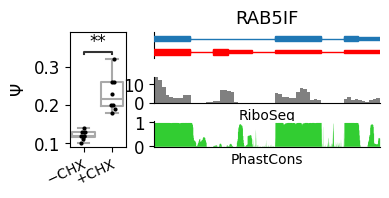

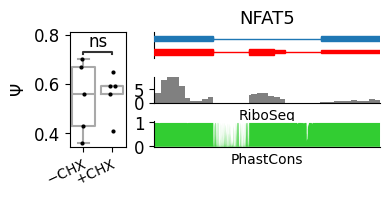

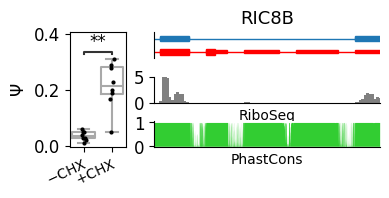

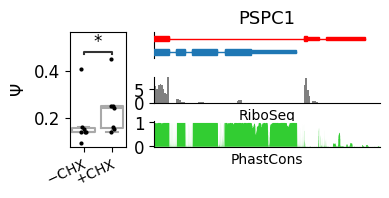

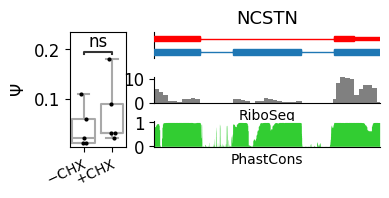

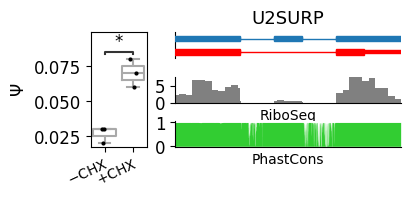

In [130]:
%%time
reload(pg)
for _,row in df.iterrows():
    trlist = None if row.gene_name not in trs.keys() else trs[row.gene_name]
    f,ax = plot(row,trs=trlist,figsize=(4,1.5))
    plt.subplots_adjust(wspace=0.2,hspace=0.7)
    ax[0].set_yticks([])
    ax[0].set_title(ax[0].get_title(),fontsize=13)
    ax[1].set_ylabel(None)
    ax[2].set_ylabel(None)
    
    ax[1].set_xlabel('RiboSeq',fontsize=10)
    ax[2].set_xlabel('PhastCons',fontsize=10)
    axs = ax[3]
    axs.set_xticklabels(axs.get_xticklabels(),rotation=25,ha='right',rotation_mode='anchor',fontsize=10)
    f.savefig(f'./figures/examples/{row.gene_name}.pdf',bbox_inches='tight',transparent=True)

In [131]:
plt.rcParams.update({'font.size': 14})

### Merge example figures

In [132]:
from pypdf import PdfReader, PdfWriter, Transformation
from pypdf._page import PageObject

files = [
    "./figures/examples/RAB5IF.pdf",
    "./figures/examples/RIC8B.pdf",
    "./figures/examples/U2SURP.pdf",
    "./figures/examples/PSPC1.pdf",
    "./figures/examples/NCSTN.pdf",
    "./figures/examples/NFAT5.pdf",
]

# overlap between images
overlap_h = 0  # frac of width
overlap_v = 0.15  # frac of height

pages = [PdfReader(f).pages[0] for f in files]

w = max(float(p.mediabox.width) for p in pages)
h = max(float(p.mediabox.height) for p in pages)

# Шаг между колонками и строками
dx = w - overlap_h*w
dy = h - overlap_v*h

canvas_width = w + dx
canvas_height = h + 2 * dy

canvas = PageObject.create_blank_page(
    width=canvas_width,
    height=canvas_height,
)

positions = [
    (0,      2 * dy),
    (dx,     2 * dy),
    (0,      dy),
    (dx,     dy),
    (0,      0),
    (dx,     0),
]

for page, (x, y) in zip(pages, positions):
    canvas.merge_transformed_page(
        page,
        Transformation().translate(x, y)
    )

writer = PdfWriter()
writer.add_page(canvas)

with open("./figures/examples/combined.pdf", "wb") as f:
    writer.write(f)

## Figure 6 (discussion)

(0.0, 1.0)

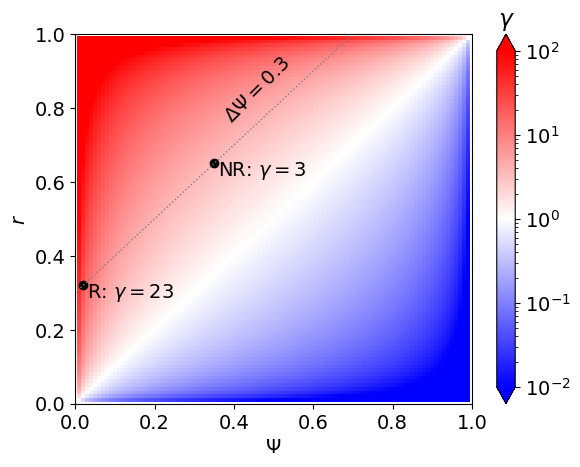

In [133]:
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.colors as colors

psi = np.linspace(0, 1, 100)
r = np.linspace(0, 1, 100)

psi = psi[1:-1]
r = r[1:-1]

PSI, R = np.meshgrid(psi, r)

gamma = hf.psir2gamma(PSI,R)

f, ax = plt.subplots()

pcm = ax.pcolormesh(
    PSI, R, gamma,
    shading='auto',
    norm=colors.LogNorm(vmax=100,vmin=0.01),
#    norm=colors.LogNorm(),
    cmap='bwr'
)

cbar = plt.colorbar(pcm, ax=ax,extend='both')
cbar.ax.set_title('$\gamma$')


ax.set_xlabel(r'$\Psi$')
ax.set_ylabel(r'$r$')

l = [0.3]
for dpsi in l:
    ax.plot([0,1],[dpsi,1+dpsi],lw=1,ls=':',c='grey')

x = np.mean(l)+0.25#(1-np.mean(l))/2
y = x+np.mean(l)
ax.text(x,y,rf'$\Delta\Psi={np.mean(l)}$',rotation=45,va='center',ha='right')

x1 = (1-np.mean(l))/2
x2 = 0.02
x = np.array([x1,x2])
y = x+np.mean(l)
ax.scatter(x,y,c='black')
g = hf.psir2gamma(x,y)
labels = [f'NR: $\\gamma={g[0]:.0f}$',f'R: $\\gamma={g[1]:.0f}$']

offset=0.01
for xi,yi,t in zip(x,y,labels):
    ax.text(xi+offset,yi+offset,t,ha='left',va='top')

#ax.legend(loc='lower center',bbox_to_anchor=(0.5,1),ncol=2)
ax.set_xlim(0,1)
ax.set_ylim(0,1)

In [134]:
f.savefig('./figures/Fig6.pdf',bbox_inches='tight')

## Supplementary 

### SF1

In [135]:
import mm
from scipy.optimize import minimize

In [136]:
bindpsi = pd.read_csv('./nmd_inactivation_data/binASE_master_table.tsv',
                      sep='\t')
ctrl = bindpsi[bindpsi.experiment=='HeLa dKD'].copy()

In [137]:
N=1000
frac = 0.5
baseline = []
for _ in range(N):
    smpl = ctrl.sample(frac=frac)
    x_control = smpl.exp_psi.to_numpy()
    y_control = smpl.ctrl_psi.to_numpy()

    a0_hat = minimize(
        mm.residuals_control,
        x0=[2],
        args = (x_control,y_control),
        bounds=[(0.01, 500)]
    ).x[0]
    baseline.append(a0_hat)

In [138]:
x_control = ctrl.exp_psi.to_numpy()
y_control = ctrl.ctrl_psi.to_numpy()

In [139]:
l,h = np.quantile(baseline,2.5/100),np.quantile(baseline,1-2.5/100)

In [140]:
x = np.linspace(0,1,100)
low,high = mm.hyperbolic_curve(x, l),mm.hyperbolic_curve(x, h)

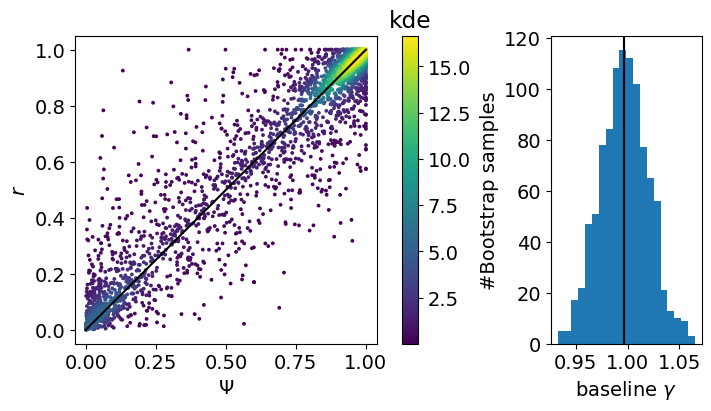

In [141]:
f,(ax,ax2) = plt.subplots(1,2,figsize=(7,4),width_ratios=(2,1),constrained_layout=True)
z,idx = hf.plot2d(y_control,x_control)
im = ax.scatter(y_control[idx],x_control[idx],c=z[idx],s=3)
cbar = plt.colorbar(im)
cbar.ax.set_title('kde')
ax2.hist(baseline,bins=20)
ax.axis('equal')
ax.set_xlabel(r'$\Psi$')
ax.set_ylabel(r'$r$')
ax2.set_ylabel('#Bootstrap samples')
ax2.set_xlabel(r'baseline $\gamma$')

med = np.median(baseline)
ax2.axvline(med,c='black')

y = np.linspace(0,1,100)
x = mm.hyperbolic_curve(y,med)
ax.plot(x,y,c='black')

In [142]:
f.savefig('./figures/SF1.pdf',bbox_inches='tight')

### SF2

[Jump here](#sf3)